# Module 2 · Day 2 · Five Labs to One Decision
Five 30-minute labs on the Titanic data. Each lab starts from the file the last one saved.

| Lab | Starts from | Saves |
|---|---|---|
| 1 Cleaning | titanic.csv | titanic_clean.csv |
| 2 NumPy | titanic_clean.csv | nothing |
| 3 EDA | titanic_clean.csv | your top-3 ranking |
| 4 Features | titanic_clean.csv | titanic_features.csv |
| 5 Pipeline | titanic.csv | titanic_ready.csv |

Every file you use today is one you made yourself, so save carefully.

When you finish, write your **lab report** (template on the LMS): explain what you found in each lab.

Run this cell first.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

---
# Lab 1 · Cleaning (30 min)
Goal: turn the raw file into a clean one, and write down **why** you made each choice.

**Task 1.** Load `titanic.csv` and print its shape.

Check: `(891, 12)`

In [2]:
df = pd.read_csv("titanic.csv")
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Task 2.** Count the gaps in each column, then the % missing.

Check: `Age 19.9 · Cabin 77.1 · Embarked 0.2`

In [3]:
gaps = df.isnull().sum()
pct = (gaps / len(df) * 100).round(1)
missing = pd.DataFrame({"gaps": gaps, "% missing": pct})
missing[missing["gaps"] > 0]

,gaps,% missing
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


**Task 3: write your decision and reason for each column with gaps.**

- **Cabin:** 77.1% missing, so filling it would mean inventing most of the column. I kept the useful part as a flag `HasCabin` (1 = cabin known) and dropped `Cabin`. A missing cabin is itself information, it mostly belongs to 2nd and 3rd class passengers.
- **Embarked:** only 2 rows missing (0.2%). Too small to be worth guessing, so I dropped those 2 rows.
- **Age:** 19.9% missing, which is too many rows to drop (177 people) and Age is clearly important. I filled it with the **median age of each class**, because the median is not pulled by a few old passengers, and first class passengers were older on average than third class.

**Task 4.** Add `HasCabin` (1 if a cabin is known, else 0), then drop `Cabin`.

Check: `HasCabin sum = 204`

In [4]:
df["HasCabin"] = df["Cabin"].notnull().astype(int)
df = df.drop(columns="Cabin")
print("HasCabin sum =", df["HasCabin"].sum())
# quick look: does knowing the cabin relate to survival?
df.groupby("HasCabin")["Survived"].mean().round(3)

HasCabin sum = 204


HasCabin
0    0.300
1    0.667
Name: Survived, dtype: float64

**Task 5.** Drop the rows with no `Embarked`.

Check: `(889, 12)`

In [5]:
# only 2 rows, so dropping them costs almost nothing
print(df[df["Embarked"].isnull()][["Name", "Pclass", "Fare"]])
df = df.dropna(subset=["Embarked"])
print(df.shape)

                                          Name  Pclass  Fare
61                         Icard, Miss. Amelie       1  80.0
829  Stone, Mrs. George Nelson (Martha Evelyn)       1  80.0
(889, 12)


**Task 6.** Fill `Age` with the median age of each class.

Check: `Age gaps: 0`

In [6]:
# median age per class before filling
class_median = df.groupby("Pclass")["Age"].median()
print(class_median)

df["Age"] = df["Age"].fillna(df.groupby("Pclass")["Age"].transform("median"))
print("Age gaps:", df["Age"].isnull().sum())

Pclass
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64
Age gaps: 0


**Task 7.** Check there are no gaps left, then save `titanic_clean.csv`.

Check: `(889, 12) and 0 gaps`

In [7]:
print(df.shape, "and", df.isnull().sum().sum(), "gaps")
df.to_csv("titanic_clean.csv", index=False)
print("saved titanic_clean.csv")

(889, 12) and 0 gaps
saved titanic_clean.csv


---
# Lab 2 · NumPy (30 min)
Goal: answer questions with arrays and masks. **NumPy only**: no groupby in this lab.

**Task 1.** Load `titanic_clean.csv`. Make arrays `survived`, `fare`, `age`, `pclass`, `sex`. Print the shape and dtype of `survived` and `fare`.

Check: `(889,) int64 · (889,) float64`

In [8]:
clean = pd.read_csv("titanic_clean.csv")

survived = clean["Survived"].to_numpy()
fare = clean["Fare"].to_numpy()
age = clean["Age"].to_numpy()
pclass = clean["Pclass"].to_numpy()
sex = clean["Sex"].to_numpy()

print(survived.shape, survived.dtype, "·", fare.shape, fare.dtype)

(889,) int64 · (889,) float64


**Task 2.** Overall survival rate with `np.mean`.

Check: `0.382`

In [9]:
overall = np.mean(survived)
print(round(overall, 3))

0.382


**Task 3.** Fare over 100: how many people, and what share survived?

Check: `53 people · 0.736`

In [10]:
rich = fare > 100
print(rich.sum(), "people ·", round(survived[rich].mean(), 3))

53 people · 0.736


**Task 4.** Women: how many, and what share survived? Then first class AND under 18.

Check: `312 · 0.74 | 12 · 0.917`

In [11]:
women = sex == "female"
print(women.sum(), "·", round(survived[women].mean(), 2), end=" | ")

first_kids = (pclass == 1) & (age < 18)
print(first_kids.sum(), "·", round(survived[first_kids].mean(), 3))

312 · 0.74 | 12 · 0.917


**Task 5.** Use `np.where` to label age ≤ 12 as "child", else "adult". Count each, then child survival.

Check: `child 69 · adult 820 · 0.58`

In [12]:
group = np.where(age <= 12, "child", "adult")
print("child", (group == "child").sum(), "· adult", (group == "adult").sum(),
      "·", round(survived[group == "child"].mean(), 2))

# for comparison
print("adult survival:", round(survived[group == "adult"].mean(), 2))

child 69 · adult 820 · 0.58
adult survival: 0.37


**Task 6.** Make age band edges with `np.linspace(0, 80, 5)`.

Check: `[ 0. 20. 40. 60. 80.]`

In [13]:
edges = np.linspace(0, 80, 5)
print(edges)

# survival in each band using the edges (still numpy only)
for lo, hi in zip(edges[:-1], edges[1:]):
    band = (age > lo) & (age <= hi)
    print(f"{int(lo)}-{int(hi)}: {band.sum()} people, survival {survived[band].mean():.2f}")

[ 0. 20. 40. 60. 80.]
0-20: 179 people, survival 0.46
20-40: 561 people, survival 0.36
40-60: 128 people, survival 0.39
60-80: 21 people, survival 0.19


**Task 7: write 2 findings as sentences, each with a number.**

1. Sex mattered a lot: 74% of the 312 women survived, while the overall rate was only 38.2%, so being a woman roughly doubled your chance.
2. Money and youth together almost guaranteed survival: 91.7% of first-class children (11 of 12) survived, and 73.6% of people who paid a fare over 100 survived, compared with 38.2% overall.

---
# Lab 3 · EDA (30 min)
Goal: find the story. **Predict first**, then check with a number or a chart.

**Task 1.** Load `titanic_clean.csv`. What is the overall survival rate (the baseline)?

Check: `0.38`

In [14]:
eda = pd.read_csv("titanic_clean.csv")
baseline = eda["Survived"].mean()
print(round(baseline, 2))

0.38


**Task 2.** Survival by `Sex`, as a bar chart.

Check: `female 0.74 · male 0.19`

Sex
female    0.74
male      0.19
Name: Survived, dtype: float64


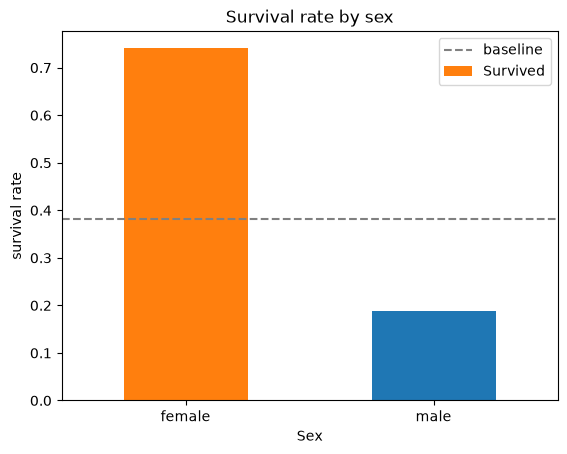

In [15]:
by_sex = eda.groupby("Sex")["Survived"].mean()
print(by_sex.round(2))

by_sex.plot(kind="bar", color=["tab:orange", "tab:blue"], rot=0)
plt.axhline(baseline, color="gray", linestyle="--", label="baseline")
plt.title("Survival rate by sex")
plt.ylabel("survival rate")
plt.legend()
plt.show()

**Task 3.** Survival by `Pclass`, as a bar chart.

Check: `0.63 · 0.47 · 0.24`

Pclass
1    0.63
2    0.47
3    0.24
Name: Survived, dtype: float64


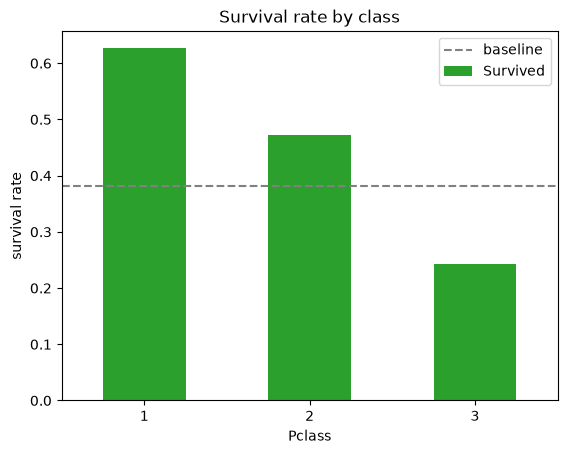

In [16]:
by_class = eda.groupby("Pclass")["Survived"].mean()
print(by_class.round(2))

by_class.plot(kind="bar", color="tab:green", rot=0)
plt.axhline(baseline, color="gray", linestyle="--", label="baseline")
plt.title("Survival rate by class")
plt.ylabel("survival rate")
plt.legend()
plt.show()

**Task 4.** Histograms of `Age` and `Fare`. Compare the mean and median of `Fare`.

Check: `Fare mean 32.1 · median 14.45`

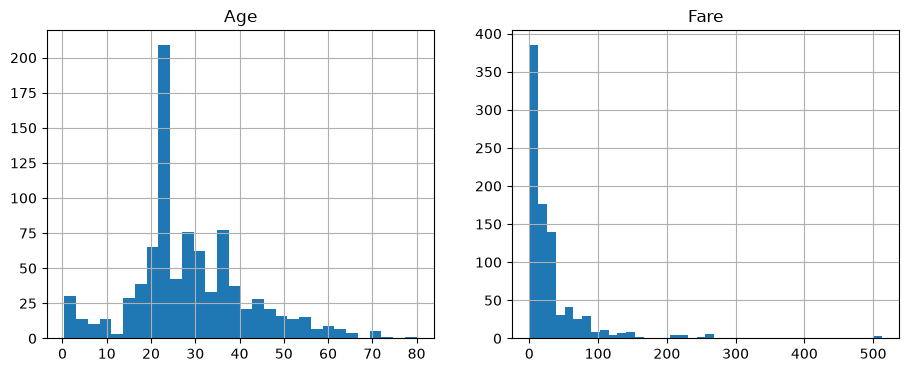

Fare mean 32.1 · median 14.45
Fare max 512.3292


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
eda["Age"].hist(bins=30, ax=ax[0])
ax[0].set_title("Age")
eda["Fare"].hist(bins=40, ax=ax[1])
ax[1].set_title("Fare")
plt.show()

print("Fare mean", round(eda["Fare"].mean(), 1), "· median", round(eda["Fare"].median(), 2))
print("Fare max", eda["Fare"].max())

**Task 5.** Pivot table: survival by `Pclass` × `Sex`.

Check: `1st-class women 0.97 · 3rd-class men 0.14`

In [18]:
pivot = eda.pivot_table(values="Survived", index="Pclass", columns="Sex", aggfunc="mean")
pivot.round(2)

Sex,female,male
Pclass,,
1,0.97,0.37
2,0.92,0.16
3,0.50,0.14


**Task 6.** Survival by `Embarked`.

Check: `C 0.55 · Q 0.39 · S 0.34`

In [19]:
by_port = eda.groupby("Embarked")["Survived"].mean()
print(by_port.round(2))

# is C high only because more first class people boarded there?
pd.crosstab(eda["Embarked"], eda["Pclass"], normalize="index").round(2)

Embarked
C    0.55
Q    0.39
S    0.34
Name: Survived, dtype: float64


Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


**Task 7: rank your top 3 factors, each with a number.**

1. **Sex**: 74% of women survived vs 19% of men (a 55-point gap, the biggest I found).
2. **Class**: 63% in 1st class vs 24% in 3rd class. The pivot shows class still matters inside each sex: 3rd-class women 50% vs 1st-class women 97%.
3. **Age (being a child)**: 58% of children (age 12 or under) survived vs 37% of adults.

Embarked looked like a factor (C 55% vs S 34%), but the crosstab shows 51% of people from C were 1st class against 20% from S, so it is mostly class in disguise. I did not rank it.

---
# Lab 4 · Features (30 min)
Goal: build new columns that show hidden patterns. **Do the tasks in order**, so your table matches Lab 5.

**Task 1.** Load `titanic_clean.csv`. Add `FamilySize = SibSp + Parch + 1`.

Check: `largest family: 11`

In [20]:
feat = pd.read_csv("titanic_clean.csv")
feat["FamilySize"] = feat["SibSp"] + feat["Parch"] + 1
print("largest family:", feat["FamilySize"].max())

largest family: 11


**Task 2.** Add `IsAlone` with `np.where` (1 if FamilySize is 1). Survival for each.

Check: `alone 0.30 · not alone 0.51`

In [21]:
feat["IsAlone"] = np.where(feat["FamilySize"] == 1, 1, 0)
print(feat.groupby("IsAlone")["Survived"].mean().round(2))

IsAlone
0    0.51
1    0.30
Name: Survived, dtype: float64


**Task 3.** Pull `Title` out of `Name`. Mlle and Ms become Miss, Mme becomes Mrs, and anything that is not Mr, Mrs, Miss or Master becomes Rare. Survival by Title.

Check: `Mrs 0.79 · Miss 0.70 · Master 0.57 · Rare 0.35 · Mr 0.16`

In [22]:
feat["Title"] = feat["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
print(feat["Title"].value_counts())

feat["Title"] = feat["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
feat["Title"] = feat["Title"].where(feat["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

feat.groupby("Title")["Survived"].agg(["count", "mean"]).sort_values("mean", ascending=False).round(2)

Title
Mr              517
Miss            181
Mrs             124
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


,count,mean
Title,,
Mrs,125,0.79
Miss,184,0.70
Master,40,0.57
Rare,23,0.35
Mr,517,0.16


**Task 4.** Add `AgeBand` with `pd.cut`: 0–12 child, 12–18 teen, 18–35 young adult, 35–60 adult, 60–80 senior. Survival by band.

Check: `child 0.58 · senior 0.19`

In [23]:
feat["AgeBand"] = pd.cut(feat["Age"], bins=[0, 12, 18, 35, 60, 80],
                         labels=["child", "teen", "young adult", "adult", "senior"])
feat.groupby("AgeBand", observed=True)["Survived"].agg(["count", "mean"]).round(2)

,count,mean
AgeBand,,
child,69,0.58
teen,70,0.43
young adult,505,0.35
adult,224,0.41
senior,21,0.19


**Task 5.** Add `SexCode` with `.map`, then dummy columns for `Embarked`.

Check: `new columns Emb_C, Emb_Q, Emb_S`

In [24]:
feat["SexCode"] = feat["Sex"].map({"male": 0, "female": 1})
emb = pd.get_dummies(feat["Embarked"], prefix="Emb", dtype=int)
feat = pd.concat([feat, emb], axis=1)
print([c for c in feat.columns if c.startswith("Emb_")])

['Emb_C', 'Emb_Q', 'Emb_S']


**Task 6.** Check the shape, then save `titanic_features.csv`.

Check: `(889, 20)`

In [25]:
print(feat.shape)
feat.to_csv("titanic_features.csv", index=False)
print("saved titanic_features.csv")

(889, 20)
saved titanic_features.csv


**Task 7: update your top-3 ranking. Did a new feature get in?**

1. **Title** (new): Mrs 79% · Miss 70% · Master 57% vs Mr 16%. It replaces Sex at the top because it holds sex *and* age: boys (Master) survived at 57% while adult men (Mr) only 16%.
2. **Class**: 63% in 1st vs 24% in 3rd.
3. **Family / IsAlone** (new): 51% of people with family survived vs 30% of people travelling alone. Age moved out of the top 3 because Title already captures the "child" effect through Master and Miss.

---
# Lab 5 · Pipeline (30 min)
Goal: Labs 1 and 4 in **one function**. Raw file in, ready table out.

**Task 1.** Write `prepare_titanic(path)`: read the file, do the Lab 1 steps, then the Lab 4 steps, then `return df`.

Check: `no output yet`

In [26]:
def prepare_titanic(path):
    df = pd.read_csv(path)

    # Lab 1: cleaning
    df["HasCabin"] = df["Cabin"].notnull().astype(int)
    df = df.drop(columns="Cabin")
    df = df.dropna(subset=["Embarked"])
    df["Age"] = df["Age"].fillna(df.groupby("Pclass")["Age"].transform("median"))

    # Lab 4: features
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = np.where(df["FamilySize"] == 1, 1, 0)

    title = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    df["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

    df["AgeBand"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 80],
                           labels=["child", "teen", "young adult", "adult", "senior"])
    df["SexCode"] = df["Sex"].map({"male": 0, "female": 1})
    emb = pd.get_dummies(df["Embarked"], prefix="Emb", dtype=int)
    df = pd.concat([df, emb], axis=1)

    df = df.reset_index(drop=True)
    return df

**Task 2.** Run it on the raw file: `df = prepare_titanic("titanic.csv")`.

Check: `(889, 20)`

In [27]:
df = prepare_titanic("titanic.csv")
print(df.shape)

(889, 20)


**Task 3.** Load `titanic_features.csv` from Lab 4. Same shape? Same columns?

Check: `True · True`

In [28]:
lab4 = pd.read_csv("titanic_features.csv")
print(df.shape == lab4.shape, "·", list(df.columns) == list(lab4.columns))

# stronger check: are the values the same too?
# (AgeBand comes back from csv as text, so compare it as text)
check = df.copy()
check["AgeBand"] = check["AgeBand"].astype(str)
print("same values:", check.equals(lab4))

True · True
same values: True


**Task 4.** Run the function a second time. Is the result the same?

Check: `True`

In [29]:
df2 = prepare_titanic("titanic.csv")
print(df.equals(df2))

True


**Task 5.** Save the result as `titanic_ready.csv`.

Check: `file saved`

In [30]:
df.to_csv("titanic_ready.csv", index=False)
print("file saved")

file saved


**Task 6.** Bonus: the `@` survival score. Female counts 2, first class 1, child 1. Survival rate for each score.

Check: `0 → 0.11 · 1 → 0.39 · 2 → 0.66 · 3 → 0.89`

In [31]:
score = (df["SexCode"] * 2) + (df["Pclass"] == 1).astype(int) + (df["Age"] <= 12).astype(int)
df["Score"] = score
df.groupby("Score")["Survived"].agg(["count", "mean"]).round(2)

,count,mean
Score,,
0,421,0.11
1,153,0.39
2,192,0.66
3,122,0.89
4,1,0.00


---
# The decision
With your group: rank the top 3 factors, one number for each, one chart, one honest limitation. 3 minutes to present.

**My decision:**
1. **Sex / Title**: 74% of women survived vs 19% of men (Title: Mrs 79%, Mr 16%).
2. **Class**: 63% of 1st class survived vs 24% of 3rd class.
3. **Travelling with family**: 51% with family vs 30% alone.

**Chart:** survival by sex (Lab 3, Task 2).

**Limitation:** 177 ages (19.9%) were filled with the class median, so every filled 3rd-class passenger is exactly 24, which can hide real child/adult differences inside the Age results.